In [1]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [68]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")

df01 = df0.loc[~df0.q45_clé.isin(["Z37Y-6JGC","QNYZ-3MH2","H5X6-KL2Z",'PS8W-TJ9P'])].drop_duplicates(subset="q45_clé")#.merge(list_affil, on = ["q45_clé", "q44_ufr_labo"], how = "left")
df01

,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,label_recherche_1,auto_lab_research_cluster,research_fields,clust_type_data,auto_clust_data,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5,hc_label
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,Etudes sociales des oeuvres culturelle,"[""SH4 L'esprit humain et sa complexité"", 'SH8 ...","['SH3', 'SH4', 'SH5', 'SH6']",Corpus textuels,"['Données textuelles ou documentaires', 'Métad...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",Humanités
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Entretiens,"['Données textuelles ou documentaires', 'Autre...",Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Psychologie
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Etudes expérimentale,"[""Données expérimentales ou d'observation"", ""D...",Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel",Psychologie
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,Histoires sociales du politique,"['SH8 Études des cultures et des arts', ""SH6 L...","['SH1', 'SH3', 'SH6', 'SH8']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Questions économiques
5,6,"Oui, un peu","Oui, systématiquement",Non;Je ne connais pas Octaviana,Non,NaN,Oui,Non,Oui,Non,...,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['LS4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['SH4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel",Psychologie
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH2', 'SH3', 'SH7']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH1', 'SH2', 'SH3', 'SH7']",Données statistiques et textutelles,"['Données statistiques', 'Données textuelles o...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,Sciences informatiques,"['PE6 Sciences informatiques et informatique',...","['PE1', 'PE6', 'PE8', 'PE11']",D

In [69]:
df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")

# Profil disciplinaire

In [70]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [71]:
gb_data, df_exp = split_multiple_choices(df01, column='q24_research_fields', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df01, column='q5_logiciel_traitement_rec', index = "q45_clé", sep = '|')


In [72]:
df_rf = df_exp[["q45_clé", 'q24_research_fields']].copy()
df_rf.loc[df_rf.q24_research_fields.isna(), "q24_research_fields"] = "Aucun sous-domaine"

df_rf["value"] = "Oui"
df_rf["question"] = 'q24_research_fields'

df_rf["nb"] = df_rf.groupby(["q24_research_fields"])["q45_clé"].transform("count")
#df_rf2 = df_rf.loc[df_rf.nb>0]
df_rf["q24_research_fields"] = df_rf.apply(lambda row: row.q24_research_fields.split(" ")[0], 1) # lower sentence
df_rf["value_int"] = 1

In [73]:
def create_term_term_matrix(data, what, list_columns, value, fill_value=0):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=fill_value)
    
    #term_term = np.dot(table, table.T) # multiplication de la transposé de
    return table

In [74]:
table = create_term_term_matrix(data = df_rf,  what ="q45_clé", list_columns=["q24_research_fields"], value="value", fill_value="Non")
table2 = create_term_term_matrix(data = df_rf,  what ="q45_clé", list_columns=["q24_research_fields"], value="value_int", fill_value=0)
table2

/tmp/ipykernel_927/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7fb90db85940> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,
/tmp/ipykernel_927/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7fb90db85940> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


q24_research_fields,LS4,LS5,LS7,PE1,PE10,PE11,PE6,PE7,PE8,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8
q45_clé,,,,,,,,,,,,,,,,,
2DRU-P3AV,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
2JQN-P9PA,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2QNC-8AAQ,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0
2Y89-7BR9,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0
32TW-JLY5,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1
YTMC-B4DP,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
ZB5S-ABHN,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0


In [75]:
!pip install fanalysis

In [76]:
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [77]:
sns.set(context='notebook', style='white', rc={'figure.figsize':(14,10)})

In [78]:
#analyse avec fanalysis
from fanalysis.mca import MCA

In [79]:
len(df_rf.loc[df_rf.q24_research_fields=="LS5"])

3

In [80]:
for col in table.columns:
    print(col)
    table[col] = table.apply(lambda row: f'{col}_{str(row[col])}', 1) # lower sentence
table

LS4
LS5
LS7
PE1
PE10
PE11
PE6
PE7
PE8
SH1
SH2
SH3
SH4
SH5
SH6
SH7
SH8


q24_research_fields,LS4,LS5,LS7,PE1,PE10,PE11,PE6,PE7,PE8,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8
q45_clé,,,,,,,,,,,,,,,,,
2DRU-P3AV,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Oui,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
2JQN-P9PA,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
2QNC-8AAQ,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Oui,SH6_Non,SH7_Oui,SH8_Non
2Y89-7BR9,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non
32TW-JLY5,LS4_Non,LS5_Non,LS7_Non,PE1_Oui,PE10_Non,PE11_Oui,PE6_Oui,PE7_Non,PE8_Oui,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Oui
YTMC-B4DP,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
ZB5S-ABHN,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non


In [81]:

var_active = [var for var in table.columns if len(df_rf.loc[df_rf.q24_research_fields==var])>9]
var_illust = [var for var in table.columns if len(df_rf.loc[df_rf.q24_research_fields==var])<=9]

table3 = table2[var_active].copy()
ind_supp =[x for x in table3.loc[table3.sum(axis=1)==0].index]
ind_actifs =[x for x in table3.loc[table3.sum(axis=1)!=0].index]

In [82]:
df_os = table.merge(df0[["q45_clé", 'label_recherche_1','hc_label']].set_index("q45_clé"), on = None, left_index= True, right_index=True, how="left")
df_os#[df_os.columns[-1:]].copy()

,LS4,LS5,LS7,PE1,PE10,PE11,PE6,PE7,PE8,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8,label_recherche_1,hc_label
q45_clé,,,,,,,,,,,,,,,,,,,
2DRU-P3AV,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Oui,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Psychologie,MIASSH
2JQN-P9PA,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Psychologie,Psychologie
2QNC-8AAQ,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Oui,SH6_Non,SH7_Oui,SH8_Non,"Individus, normes, société",Dynamiques spaciales
2Y89-7BR9,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non,Psychologie,"Langues, langage et communication"
32TW-JLY5,LS4_Non,LS5_Non,LS7_Non,PE1_Oui,PE10_Non,PE11_Oui,PE6_Oui,PE7_Non,PE8_Oui,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Sciences informatiques,MIASSH
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Oui,Histoires sociales du politique,Questions économiques
YTMC-B4DP,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Psychologie sociale,Psychologie
ZB5S-ABHN,LS4_Non,LS5_Non,LS7_Non,PE1_Non,PE10_Non,PE11_Non,PE6_Non,PE7_Non,PE8_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non,Psychologie,"Langues, langage et communication"


In [83]:

#récupération des variables actives
DActives = df_os[var_active].loc[df_os.index.isin(ind_actifs)].copy()
#print(DActives)
Dillustratives =  df_os[var_illust+['label_recherche_1','hc_label']].loc[df_os.index.isin(ind_actifs)].copy()
#récupération des infos - nombre de variables
p = DActives.shape[1]
print(p)
#nombre d'observations
n = DActives.shape[0]
print(p, n)
#codage en 0/1
X = pd.get_dummies(DActives,prefix='',prefix_sep='', dtype=int)

M = X.shape[1]
X

9
9 116


,PE6_Non,PE6_Oui,SH1_Non,SH1_Oui,SH2_Non,SH2_Oui,SH3_Non,SH3_Oui,SH4_Non,SH4_Oui,SH5_Non,SH5_Oui,SH6_Non,SH6_Oui,SH7_Non,SH7_Oui,SH8_Non,SH8_Oui
q45_clé,,,,,,,,,,,,,,,,,,
2DRU-P3AV,0,1,1,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0
2JQN-P9PA,1,0,1,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0
2QNC-8AAQ,1,0,0,1,1,0,0,1,1,0,0,1,1,0,0,1,1,0
2Y89-7BR9,1,0,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0
32TW-JLY5,0,1,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,1,0,0,1,1,0,0,1,1,0,1,0,1,0,1,0,0,1
YTMC-B4DP,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0,1,0
ZB5S-ABHN,1,0,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0


In [84]:
acm = MCA(row_labels=DActives.index,var_labels=DActives.columns)
acm.fit(DActives.values)
#propriétés
print(dir(acm))
np.transpose(acm.eig_)


['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_binarization', '_compute_stats', '_compute_svd', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_params', 'c_', 'col_contrib_', 'col_coord_', 'col_cos2_', 'col_labels', 'col_labels_', 'col_labels_short_', 'col_labels_short_temp_', 'col_labels_

array([[2.14070489e-01, 2.14070489e+01, 2.14070489e+01],
       [1.74892714e-01, 1.74892714e+01, 3.88963203e+01],
       [1.20823513e-01, 1.20823513e+01, 5.09786716e+01],
       [1.12372812e-01, 1.12372812e+01, 6.22159528e+01],
       [1.00417666e-01, 1.00417666e+01, 7.22577194e+01],
       [8.91998183e-02, 8.91998183e+00, 8.11777013e+01],
       [7.74443015e-02, 7.74443015e+00, 8.89221314e+01],
       [6.72502509e-02, 6.72502509e+00, 9.56471565e+01],
       [4.35284351e-02, 4.35284351e+00, 1.00000000e+02]])

In [85]:
#nombre max de facteurs
if M > p:
    Hmax = M - p
else:
    Hmax = p
print(M, Hmax)
#valeurs propres
valeurs_propres = pd.DataFrame(np.transpose(acm.eig_),columns=['Val_P','%','Cumul %'],index=range(1,Hmax+1))
valeurs_propres

18 9


,Val_P,%,Cumul %
1,0.214070,21.407049,21.407049
2,0.174893,17.489271,38.896320
3,0.120824,12.082351,50.978672
4,0.112373,11.237281,62.215953
5,0.100418,10.041767,72.257719
6,0.089200,8.919982,81.177701
7,0.077444,7.744430,88.922131
8,0.067250,6.725025,95.647156
9,0.043528,4.352844,100.000000


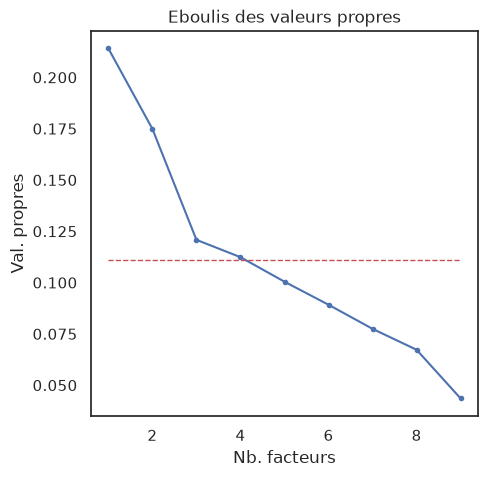

In [86]:
#librairie graphique
import matplotlib.pyplot as plt
#éboulis des v.p.
fix,ax = plt.subplots(figsize=(5,5))
ax.plot(range(1,Hmax+1),acm.eig_[0],".-")
ax.set_xlabel("Nb. facteurs")
ax.set_ylabel("Val. propres")
plt.title("Eboulis des valeurs propres")
#seuil - Règle de Kaiser
ax.plot([1,Hmax],[1/p,1/p],"r--",linewidth=1)
plt.show()

## Correction de Benzecri

In [87]:
#récupérer les valeurs propres supérieur à (1/p)
lambada = acm.eig_[0][acm.eig_[0]>1/p]
print(lambada)
#appliquer la correction
lambada_prim = ((p/(p-1))*(lambada-1/p))**2
print(lambada_prim)
#faire la somme
S_prim = np.sum(lambada_prim)
print(S_prim)

[0.21407049 0.17489271 0.12082351 0.11237281]
[1.34164268e-02 5.14868001e-03 1.19387358e-04 2.01473500e-06]
0.01868650894221271


In [88]:
#et produire les pourcentages
percent_prim = lambada_prim/S_prim*100
#affichage

eigen_val_benz = pd.DataFrame(np.transpose(np.array([lambada_prim,percent_prim,np.cumsum(percent_prim)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1))
eigen_val_benz

,Val.P,%,Cumul %
1,0.013416,71.797396,71.797396
2,0.005149,27.552926,99.350322
3,0.000119,0.638896,99.989218
4,0.000002,0.010782,100.000000


In [89]:
#somme corrigée de Greenacre (S’’)
S2nd = p/(p-1)*(np.sum(acm.eig_[0]**2)-(M-p)/(p**2))
print(S2nd)
#pourcentage corrigé Greenacre
percent_2nd = lambada_prim/S2nd

#affichage
eigen_val_greenacre = pd.DataFrame(np.transpose(np.array([lambada_prim,percent_2nd,np.cumsum(percent_2nd)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1))
print(eigen_val_greenacre)

0.02585671963808301
      Val.P         %   Cumul %
1  0.013416  0.518876  0.518876
2  0.005149  0.199123  0.717999
3  0.000119  0.004617  0.722617
4  0.000002  0.000078  0.722694


In [90]:
len(acm.col_coord_[:,:2])

18

In [91]:
#affichage des coordonnées
print(pd.DataFrame(acm.col_coord_[:,:2],index=X.columns,columns=['Coord.F1','Coord.F2']))

         Coord.F1  Coord.F2
PE6_Non  0.126392  0.162206
PE6_Oui -0.736045 -0.944613
SH1_Non -0.282066 -0.016395
SH1_Oui  1.205193  0.070053
SH2_Non -0.258978  0.008957
SH2_Oui  1.409994 -0.048766
SH3_Non -0.664631 -0.377887
SH3_Oui  0.521479  0.296496
SH4_Non  0.339247 -0.077257
SH4_Oui -0.669796  0.152532
SH5_Non  0.169551 -0.273292
SH5_Oui -0.586907  0.946010
SH6_Non  0.047627 -0.403401
SH6_Oui -0.182569  1.546371
SH7_Non -0.291138 -0.128829
SH7_Oui  1.177211  0.520919
SH8_Non  0.220433 -0.402524
SH8_Oui -0.470655  0.859443


In [92]:
df_rows = acm.row_topandas()


df_cols = acm.col_topandas()
dict_lab_short = {}
for lab in df_cols.index:
    lab_split = lab.split("_")
    dict_lab_short[lab] = "_".join(lab_split[1:])

df_cols["label"] = df_cols.index.map(dict_lab_short.get)
df_cols[['col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)



,col_contrib_dim1,col_contrib_dim2,col_cos2_dim1,col_cos2_dim2
SH2_SH2_Oui,16.012146,0.023444,0.365158,0.000437
SH1_SH1_Oui,14.298105,0.059130,0.339944,0.001149
SH7_SH7_Oui,14.261952,3.418191,0.342731,0.067110
SH3_SH3_Non,10.080305,3.988611,0.346591,0.112042
SH3_SH3_Oui,7.909163,3.129526,0.346591,0.112042
SH4_SH4_Oui,7.828739,0.496953,0.227226,0.011784
PE6_PE6_Oui,4.120979,8.307770,0.093030,0.153222
SH5_SH5_Oui,4.007330,12.743617,0.099511,0.258537
SH4_SH4_Non,3.965206,0.251703,0.227226,0.011784
SH8_SH8_Oui,3.667320,14.968004,0.103748,0.345947


## Ajout variables illustratives

In [96]:
df_coord = pd.DataFrame(acm.row_coord_[:,:2],index=X.index,columns=['F1','F2'])
df_coord['hc_label'] = Dillustratives.hc_label
df_coord['champ'] = Dillustratives.label_recherche_1


In [97]:
#calcul des moyennes conditionnelles
GBar = pd.pivot_table(df_coord,values=['F1','F2'],index="champ",aggfunc='mean')
GBar2 = pd.pivot_table(df_coord,values=['F1','F2'],index="hc_label",aggfunc='mean')
print(GBar2)

                                         F1        F2
hc_label                                             
Dynamiques spaciales               0.475693  0.136835
Etudes des arts et de la culture  -0.340297  0.205080
Histoires                         -0.187194  0.177318
Humanités                         -0.424341  0.917510
Langues, langage et communication -0.228221  0.019108
MIASSH                            -0.339497 -0.475685
Normes et gouvernances             0.740398  0.005069
Psychologie                       -0.289916 -0.279992
Questions économiques              0.358182  0.139467
Sciences info. com.                0.142299 -0.221594


In [117]:
#coordonnées factorielles des modalités - Solution 1
Gv1 = GBar.values/np.sqrt(acm.eig_[0][2:4])
Gv1 = pd.DataFrame(Gv1,index=GBar.index,columns=GBar.columns)
Gv2 = GBar2.values/np.sqrt(acm.eig_[0][2:4])
Gv2 = pd.DataFrame(Gv2,index=GBar2.index,columns=GBar2.columns)
print(Gv2)

                                         F1        F2
hc_label                                             
Dynamiques spaciales               1.368520  0.408194
Etudes des arts et de la culture  -0.978998  0.611776
Histoires                         -0.538537  0.528960
Humanités                         -1.220784  2.737035
Langues, langage et communication -0.656567  0.057000
MIASSH                            -0.976699 -1.419020
Normes et gouvernances             2.130049  0.015121
Psychologie                       -0.834057 -0.835248
Questions économiques              1.030451  0.416044
Sciences info. com.                0.409379 -0.661040


## Coefficient de corrélation avec facteur des variables illustratives

In [118]:
var_ill_x = []
var_ill_y = []
for var in ["champ","hc_label"]:
    n_g = pd.pivot_table(df_coord,values=['F1','F2'],index=var,aggfunc='count')
    n = np.sum(n_g.F1)
    var_ill_x.append(np.sum((n_g.F1/n)*(GBar.F1**2))/acm.eig_[0][0])
    var_ill_y.append(np.sum((n_g.F2/n)*(GBar.F2**2))/acm.eig_[0][0])

dict_hc_label={}
for n, x in enumerate(df_coord.hc_label.unique()):
    dict_hc_label[x] = n
df_coord["id_hc_label"] = df_coord.hc_label.map(dict_hc_label.get)

# Graphique des individus

In [119]:
import matplotlib.cm as cm
import matplotlib as mpl




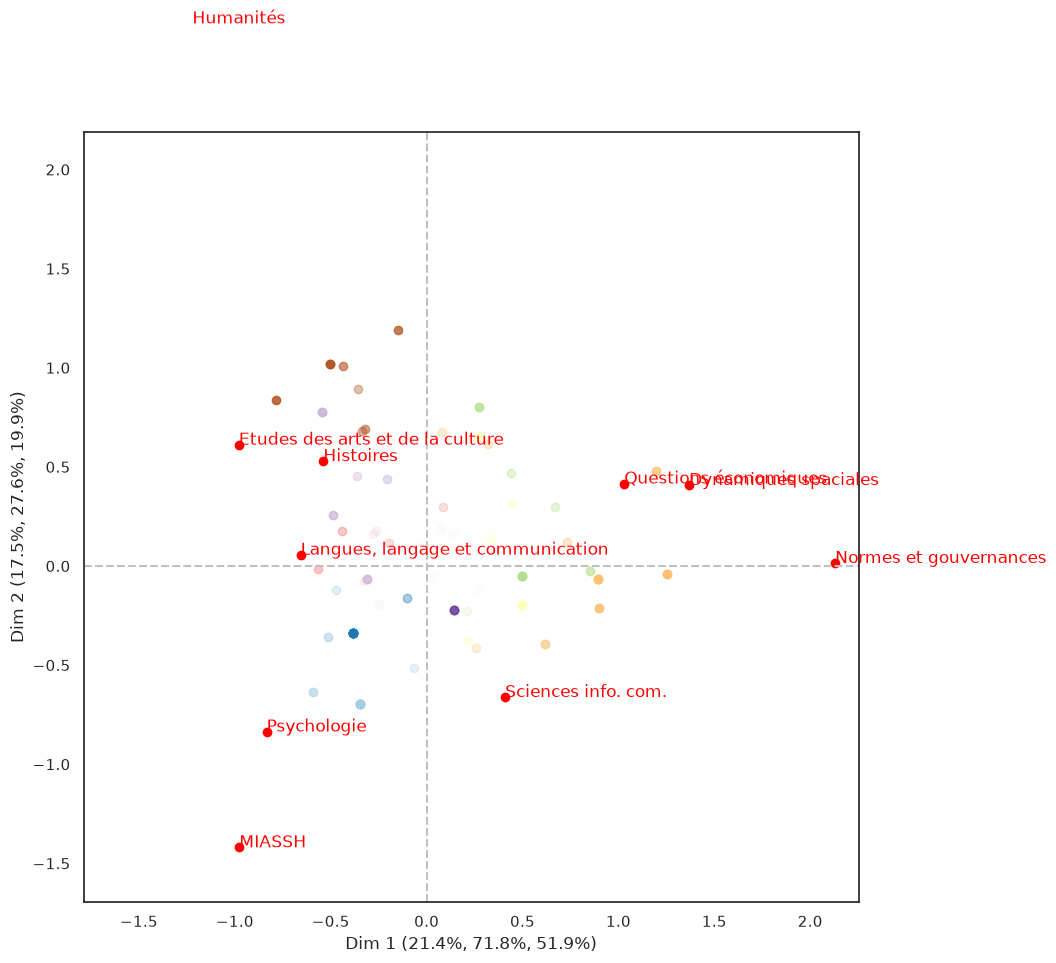

In [137]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))

dim_x = 1
dim_y = 2
min_abs = np.min(df_rows[f"row_coord_dim{dim_x}"])-1
max_abs = np.max(df_rows[f"row_coord_dim{dim_x}"])+1
min_ord = np.min(df_rows[f"row_coord_dim{dim_y}"])-1
max_ord = np.max(df_rows[f"row_coord_dim{dim_y}"])+1

cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 10))

c_label =[colors_map[i] for n, i in enumerate(df_coord.id_hc_label)]

var_illustratives = 'hc_label'

# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

#ax[0].subtitle("Représentation des points-modalités")
for i in range(df_rows.shape[0]):
    ax.scatter(acm.row_coord_[i,dim_x-1],acm.row_coord_[i,dim_y-1],color=c_label[i], alpha=(acm.row_cos2_[i,dim_x-1]+acm.row_cos2_[i,dim_y-1]))

if var_illustratives != False:
    df_coord = pd.DataFrame(acm.row_coord_[:,dim_x-1:dim_y],index=X.index,columns=['F1','F2'])
    df_coord[var_illustratives] = Dillustratives.hc_label
    #calcul des moyennes conditionnelles
    GBar = pd.pivot_table(df_coord,values=['F1','F2'],index=var_illustratives,aggfunc='mean')
    Gv1 = GBar.values/np.sqrt(acm.eig_[0][2:4])
    Gv1 = pd.DataFrame(Gv1,index=GBar.index,columns=GBar.columns)
    
    for i in Gv1.index:
        ax.scatter(Gv1.loc[i].iloc[0],Gv1.loc[i].iloc[1],color='red')
        ax.text(Gv1.loc[i].iloc[0],Gv1.loc[i].iloc[1],i,color='red')

else:
    pass




plt.show()

## Graphique des variables

/tmp/ipykernel_927/1475263511.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cols1["cos_cumsum"] = df_cols[f"col_cos2_dim{dim_x}"]+df_cols[f"col_cos2_dim{dim_y}"]


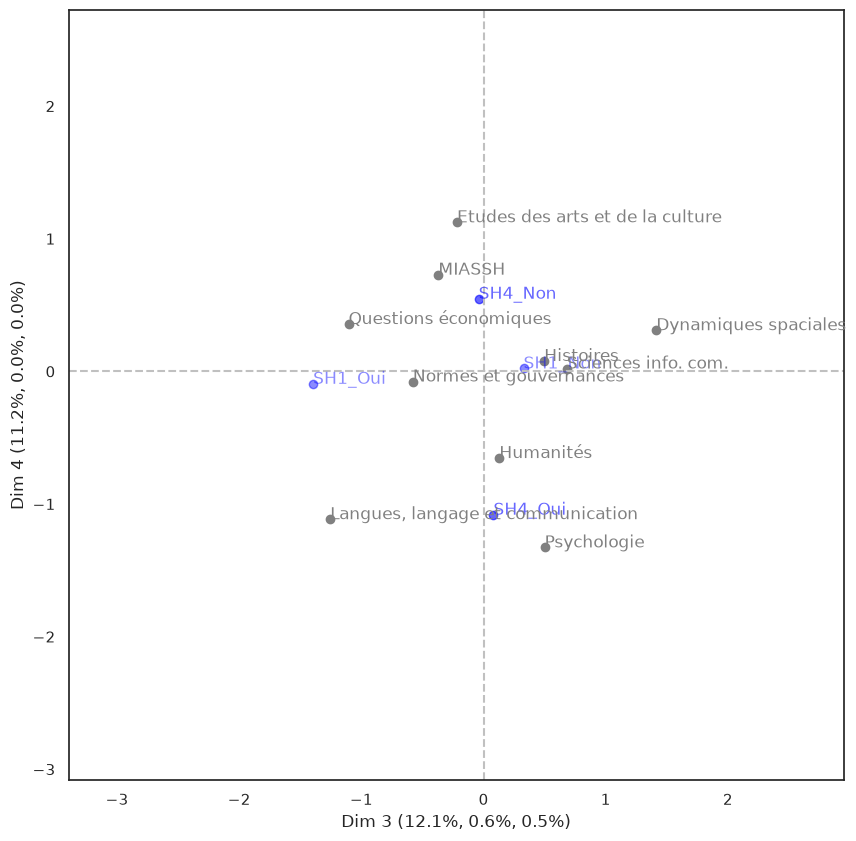

In [141]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))

dim_x = 3
dim_y = 4
min_abs = np.min(df_cols[f"col_coord_dim{dim_x}"])-2
max_abs = np.max(df_cols[f"col_coord_dim{dim_x}"])+2
min_ord = np.min(df_cols[f"col_coord_dim{dim_y}"])-2
max_ord = np.max(df_cols[f"col_coord_dim{dim_y}"])+2

var_illustratives = 'hc_label'

# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

df_cols1 = df_cols.loc[df_cols[f"col_cos2_dim{dim_x}"]+df_cols[f"col_cos2_dim{dim_y}"]>0.4]
df_cols1["cos_cumsum"] = df_cols[f"col_cos2_dim{dim_x}"]+df_cols[f"col_cos2_dim{dim_y}"]
#ax[0].subtitle("Représentation des points-modalités")
for i in range(df_cols1.shape[0]):
    ax.scatter(df_cols1[f"col_coord_dim{dim_x}"].iloc[i],df_cols1[f"col_coord_dim{dim_y}"].iloc[i],color="blue", alpha=df_cols1["cos_cumsum"].iloc[i])
    ax.text(df_cols1[f"col_coord_dim{dim_x}"].iloc[i],df_cols1[f"col_coord_dim{dim_y}"].iloc[i],df_cols1.label.iloc[i],color="blue",  alpha=df_cols1["cos_cumsum"].iloc[i])

if var_illustratives != False:
    df_coord1 = pd.DataFrame(acm.row_coord_[:,dim_x-1:dim_y],index=X.index,columns=['F1','F2'])
    df_coord1[var_illustratives] = Dillustratives.hc_label
    #calcul des moyennes conditionnelles
    GBar = pd.pivot_table(df_coord1,values=['F1','F2'],index=var_illustratives,aggfunc='mean')
    Gv1 = GBar.values/np.sqrt(acm.eig_[0][dim_x-1:dim_y])
    Gv1 = pd.DataFrame(Gv1,index=GBar.index,columns=GBar.columns)
    
    for i in Gv1.index:
        ax.scatter(Gv1.loc[i].iloc[0],Gv1.loc[i].iloc[1],color='grey')
        ax.text(Gv1.loc[i].iloc[0],Gv1.loc[i].iloc[1],i,color='grey')
else:
    pass




plt.show()

In [147]:
import datamapplot

In [165]:
df_coord= pd.DataFrame(acm.row_coord_[:,:2],index=X.index,columns=['F1','F2'])
df_coord['hc_label'] = Dillustratives.hc_label

dict_hc_label={}
for n, x in enumerate(df_coord.hc_label.unique()):
    dict_hc_label[x] = n
df_coord["id_hc_label"] = df_coord.hc_label.map(dict_hc_label.get)
lab = [i for n, i in enumerate(df_coord.hc_label)]

data_map = acm.row_coord_[:,:2]
data_map.shape
data_label = np.array(lab, dtype="object")


(<Figure size 1000x1000 with 1 Axes>, <Axes: >)

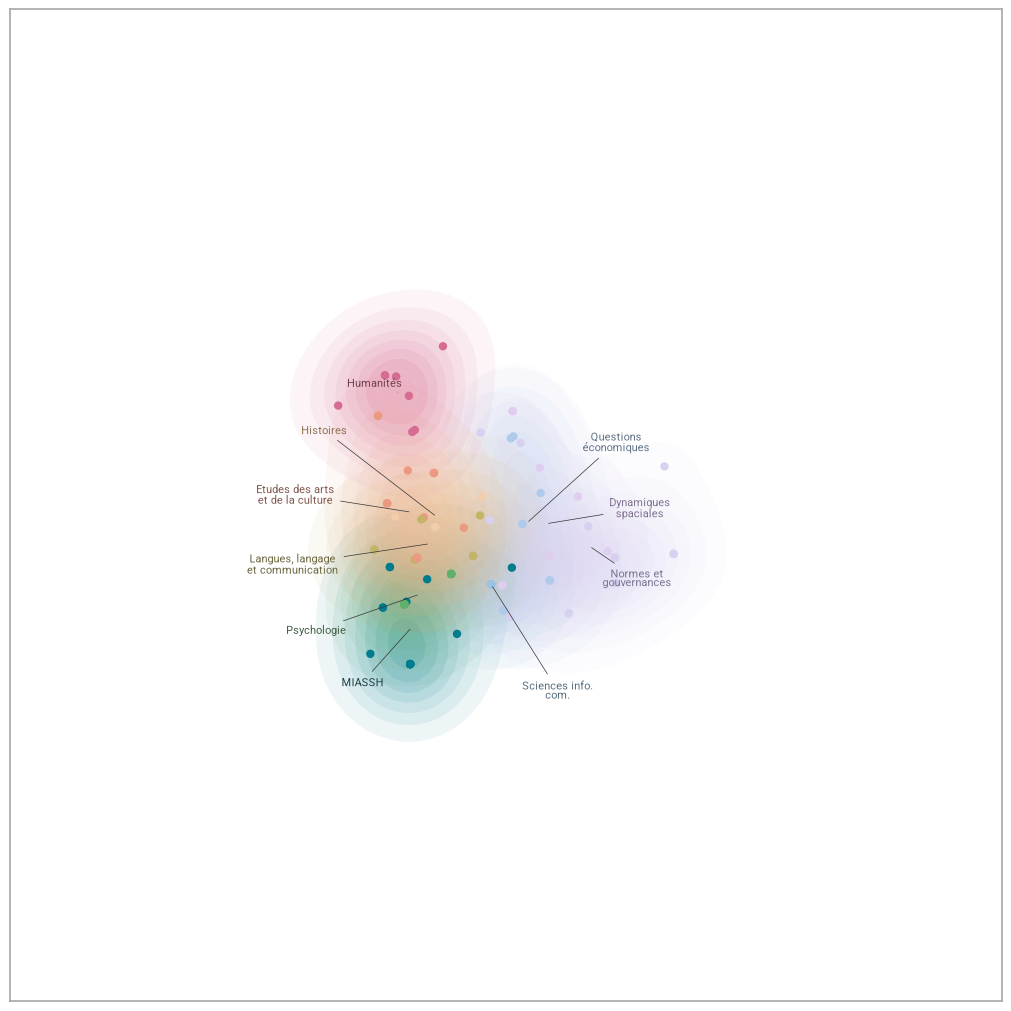

In [166]:
datamapplot.create_plot(data_map, data_label)

In [39]:
print(pd.DataFrame(np.cumsum(acm.col_cos2_[:,:4],axis=1),index=df_cols.index,columns=['Cos2.F1','Cum(Cos2).F2', 'Cum(Cos2).F3', 'Cum(Cos2).F4']))

              Cos2.F1  Cum(Cos2).F2  Cum(Cos2).F3  Cum(Cos2).F4
PE6_PE6_Non  0.093030      0.246252      0.263938      0.346094
PE6_PE6_Oui  0.093030      0.246252      0.263938      0.346094
SH1_SH1_Non  0.339944      0.341093      0.796889      0.798946
SH1_SH1_Oui  0.339944      0.341093      0.796889      0.798946
SH2_SH2_Non  0.365158      0.365595      0.478594      0.487333
SH2_SH2_Oui  0.365158      0.365595      0.478594      0.487333
SH3_SH3_Non  0.346591      0.458633      0.514861      0.553490
SH3_SH3_Oui  0.346591      0.458633      0.514861      0.553490
SH4_SH4_Non  0.227226      0.239010      0.242270      0.833924
SH4_SH4_Oui  0.227226      0.239010      0.242270      0.833924
SH5_SH5_Non  0.099511      0.358048      0.566864      0.602350
SH5_SH5_Oui  0.099511      0.358048      0.566864      0.602350
SH6_SH6_Non  0.008695      0.632503      0.635146      0.639744
SH6_SH6_Oui  0.008695      0.632503      0.635146      0.639744
SH7_SH7_Non  0.342731      0.409841     

In [40]:
acm.col_contrib_[:,[0,2]]

array([[ 0.70764284,  0.23836275],
       [ 4.12097891,  1.38811251],
       [ 3.34636507,  7.94952956],
       [14.29810531, 33.96617174],
       [ 2.94100647,  1.61249337],
       [16.01214633,  8.77913054],
       [10.08030516,  2.89742442],
       [ 7.90916251,  2.27336378],
       [ 3.96520572,  0.10079437],
       [ 7.82873949,  0.19900427],
       [ 1.15767323,  4.30413853],
       [ 4.0073304 , 14.89894105],
       [ 0.09337475,  0.05029023],
       [ 0.35793655,  0.19277921],
       [ 3.52714934,  4.05024023],
       [14.26195166, 16.37705831],
       [ 1.71760579,  0.23034577],
       [ 3.66732047,  0.49181935]])

In [41]:
#récupération des contribution sous une forme exploitable - 2 facteurs
contrib12 = pd.DataFrame(acm.col_contrib_[:,[0,1]],index=X.columns)
print(contrib12)

#**calcul des carrés des rapports de corrélation par variable sur les 2 facteurs**
#structure pour les eta2
#structure pour les eta2
cols=len(table[var_active].columns)
eta2 = np.zeros((cols,2))
#pour chaque facteur
for h in range(2):
    #pour chaque variable
    for j in range(cols):
        eta2[j,h] = (p*acm.eig_[0][h]*np.sum(contrib12.loc[np.unique(table[var_active].iloc[:,j])][h]))/100
            #affichage

print(pd.DataFrame(eta2,index=table[var_active].columns[:],columns=['F1','F2']))



                 0          1
PE6_Non   0.707643   1.426587
PE6_Oui   4.120979   8.307770
SH1_Non   3.346365   0.013839
SH1_Oui  14.298105   0.059130
SH2_Non   2.941006   0.004306
SH2_Oui  16.012146   0.023444
SH3_Non  10.080305   3.988611
SH3_Oui   7.909163   3.129526
SH4_Non   3.965206   0.251703
SH4_Oui   7.828739   0.496953
SH5_Non   1.157673   3.681489
SH5_Oui   4.007330  12.743617
SH6_Non   0.093375   8.199546
SH6_Oui   0.357937  31.431594
SH7_Non   3.527149   0.845359
SH7_Oui  14.261952   3.418191
SH8_Non   1.717606   7.010331
SH8_Oui   3.667320  14.968004
                           F1        F2
q24_research_fields                    
PE6                  0.093030  0.153222
SH1                  0.339944  0.001149
SH2                  0.365158  0.000437
SH3                  0.346591  0.112042
SH4                  0.227226  0.011784
SH5                  0.099511  0.258537
SH6                  0.008695  0.623808
SH7                  0.342731  0.067110
SH8                  0.103748 

NameError: name 'champ_cor_x' is not defined

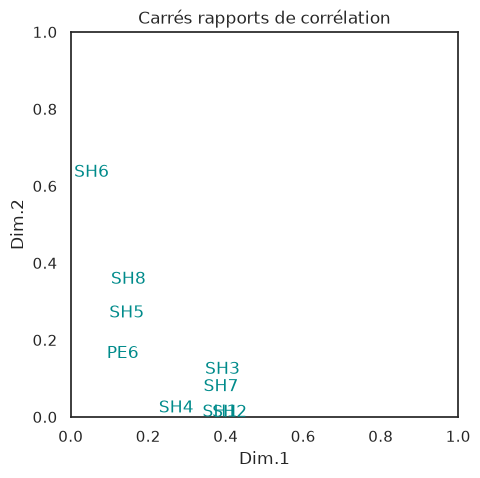

In [42]:
fix,ax = plt.subplots(figsize=(5,5))
ax.axis([0,+1,0,+1])
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Carrés rapports de corrélation")
for i in range(cols):
    ax.text(eta2[i,0],eta2[i,1],df_os[var_active].columns[i],color='darkcyan')

ax.text(champ_cor_x, champ_cor_y, "champ", color ="red")
plt.show()

In [43]:
print(df0.auto_lab_research_cluster.value_counts().to_markdown())

| auto_lab_research_cluster                                                                                                                            |   count |
|:-----------------------------------------------------------------------------------------------------------------------------------------------------|--------:|
| ["SH4 L'esprit humain et sa complexité", 'SH8 Études des cultures et des arts', 'SH5 Textes et concepts']                                            |      19 |
| ["SH4 L'esprit humain et sa complexité", 'LS5 Neurosciences et troubles du système nerveux', 'SH5 Textes et concepts']                               |      18 |
| ['SH2 Institutions, gouvernance et systèmes juridiques', 'SH1 Individus, marchés et organisations', 'SH7 Mobilité humaine, environnement et espace'] |      16 |
| ['SH5 Textes et concepts', 'SH8 Études des cultures et des arts', "SH6 L'étude du passé humain"]                                                     |      13 |
| ['SH8 Études des cul

In [44]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage

In [45]:
# Extract the row coordinates (numerical representation of your rows)
acm.row_coord_



array([[-5.91975441e-01, -6.33785678e-01,  2.52229040e-03, ...,
        -1.16660919e-04, -2.63761384e-01, -2.48198197e-01],
       [-3.84862960e-01, -3.39717317e-01,  1.22726149e-01, ...,
         1.88153989e-01, -4.16594449e-02, -1.54903192e-01],
       [ 6.70420312e-01,  2.97958268e-01, -2.86100666e-01, ...,
         6.30785014e-03,  1.92925996e-01, -2.92938321e-01],
       ...,
       [-5.66524973e-01, -1.57636529e-02, -2.27552968e-01, ...,
         2.98487548e-01,  2.29024044e-01,  6.03575267e-02],
       [-3.49655797e-01, -6.94837732e-01, -3.61120857e-02, ...,
         2.92285231e-02, -2.73135784e-01,  3.69388514e-02],
       [-3.57418532e-01,  8.95293591e-01,  1.62612929e-01, ...,
        -5.74333184e-02, -1.00437640e-01, -3.51941974e-01]],
      shape=(116, 9))

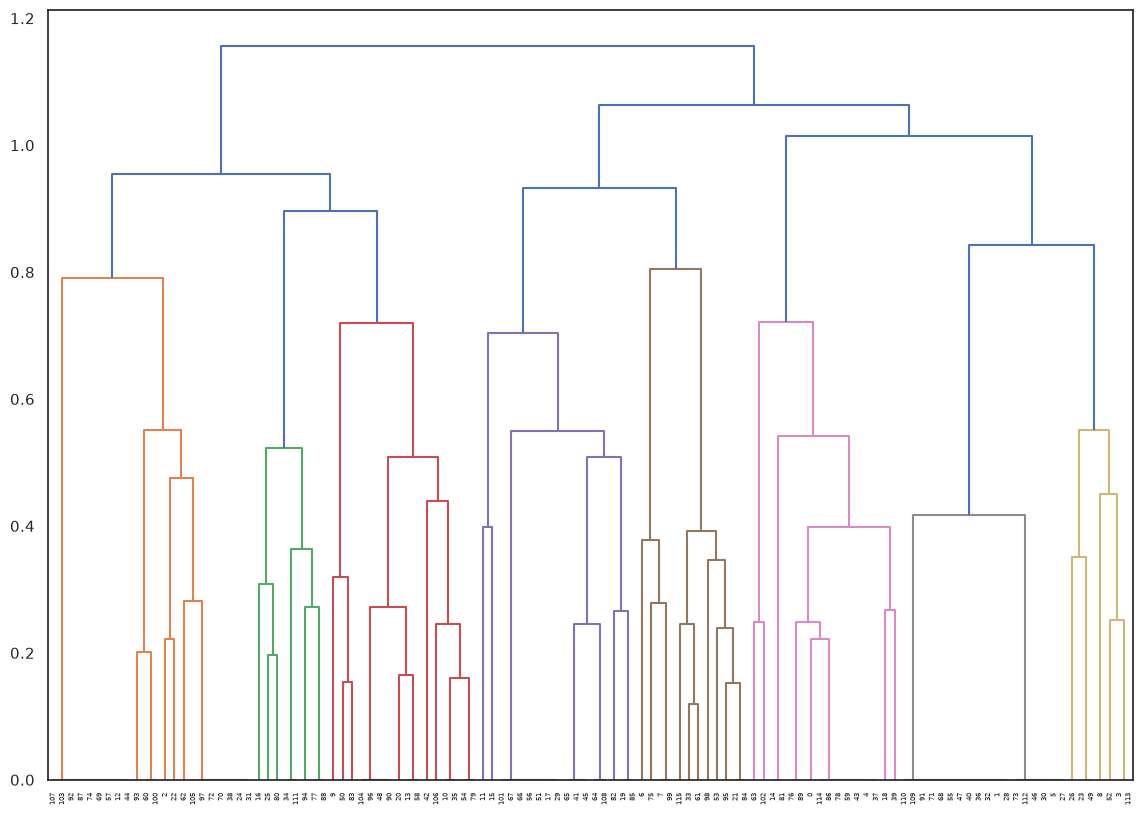

In [46]:


x = [4, 5, 10, 4, 3, 11, 14 , 6, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]

data = list(zip(x, y))

linkage_data = linkage(acm.row_coord_, method='average', metric='cosine')
dendrogram(linkage_data)

plt.show() 

[0 1 7 1 0 6 8 8 7 6 5 4 6 5 0 6 7 4 0 8 5 3 2 7 2 7 4 6 1 4 6 2 1 3 7 5 1
 0 2 0 1 4 5 0 6 4 6 1 5 7 3 4 6 3 5 1 4 6 5 0 2 3 2 0 4 4 4 4 1 6 2 1 2 6
 6 8 0 7 0 5 7 0 8 3 3 8 0 6 7 0 5 1 6 2 7 3 5 2 3 8 2 4 5 6 5 2 5 6 4 1 1
 7 6 1 0 3]


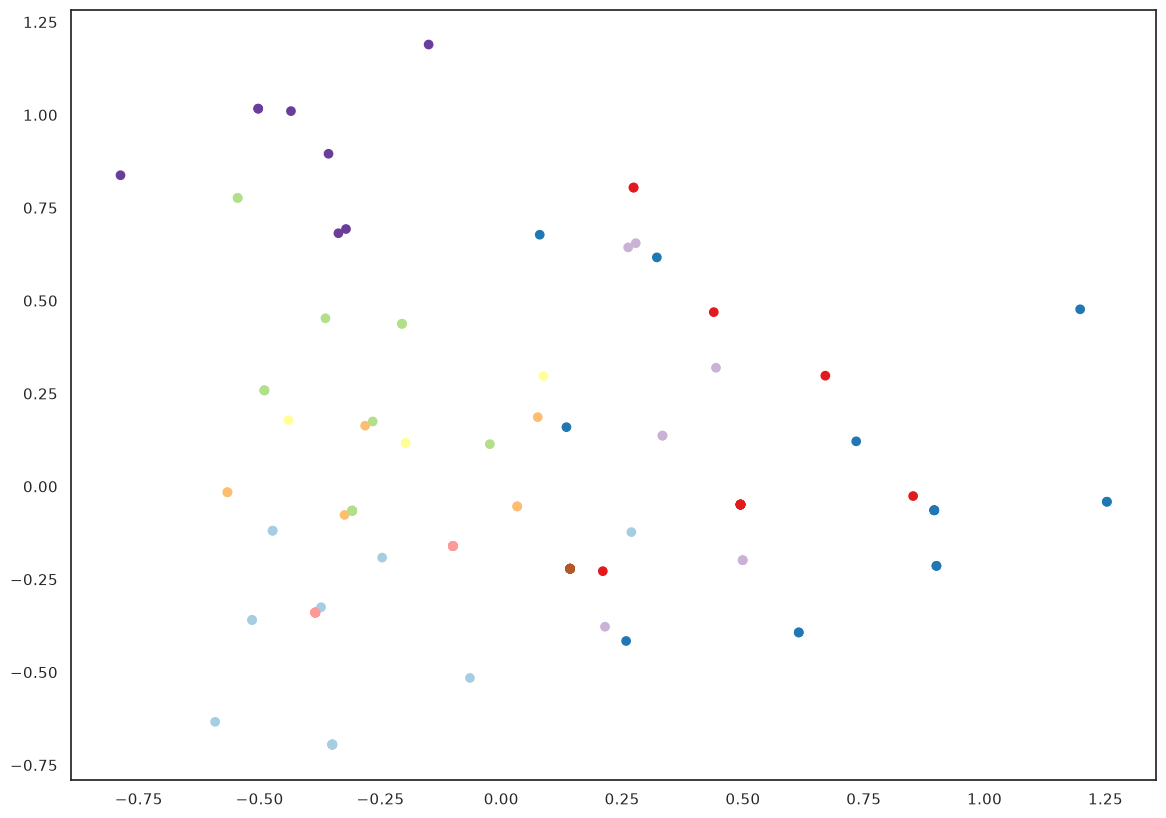

In [47]:
from sklearn.cluster import AgglomerativeClustering

x = acm.row_coord_[:,0]
y = acm.row_coord_[:,1]

data = list(zip(x, y))

hierarchical_cluster = AgglomerativeClustering(n_clusters=10, metric="cosine",linkage="average")
labels = hierarchical_cluster.fit_predict(acm.row_coord_[:,:])
kmeans = KMeans(n_clusters=9, random_state=42, n_init='auto')
labels_k = kmeans.fit_predict(acm.row_coord_[:,:])


cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 10))

c_label =[colors_map[i] for i in labels]


print(labels_k)
plt.scatter(x, y, c=c_label)

plt.show() 

In [51]:
DActives["kmeans"] = kmeans.fit_predict(acm.row_coord_[:,:])
DActives["hierarcical_clust_all"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:])
#DActives["hierarcical_clust_all_9"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:])

In [62]:
DActives.loc[DActives.hierarcical_clust_all==9]

,PE6,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8,kmeans,hierarcical_clust_all,hc_all
q45_clé,,,,,,,,,,,,
572G-RBZC,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
E3YL-PHZV,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
HKN6-95PQ,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
MXD6-JC3F,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
PQML-4NVQ,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
R9R6-P7CN,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
S3JS-37LL,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
VTX9-R7JQ,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.
XA8V-2558,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,6,9,Sciences info. com.


In [63]:
dict_label_hc_all ={0:"MIASSH",
                1:"Normes et gouvernances",
                2:"Etudes des arts et de la culture",
                3:"Psychologie",
                4:"Dynamiques spaciales",
                5:"Langues, langage et communication",
                6:"Questions économiques",
                7:"Humanités",
                8:"Histoires",
                9:"Sciences info. com.",
                   }

DActives["hc_all"]=DActives.hierarcical_clust_all.map(dict_label_hc_all.get)


In [64]:
df0["hc_label"] = df0.q45_clé.map(dict(zip(DActives.index, DActives.hc_all)))
df0

,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,label_recherche_1,auto_lab_research_cluster,research_fields,clust_type_data,auto_clust_data,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5,hc_label
0,1,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,NaN,NaN,NaN,Données textuelles et observations,"['Données textuelles ou documentaires', ""Donné...",NaN,NaN,NaN,NaN,NaN
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,Etudes sociales des oeuvres culturelle,"[""SH4 L'esprit humain et sa complexité"", 'SH8 ...","['SH3', 'SH4', 'SH5', 'SH6']",Corpus textuels,"['Données textuelles ou documentaires', 'Métad...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",Humanités
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Entretiens,"['Données textuelles ou documentaires', 'Autre...",Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Psychologie
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Etudes expérimentale,"[""Données expérimentales ou d'observation"", ""D...",Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel",Psychologie
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,Histoires sociales du politique,"['SH8 Études des cultures et des arts', ""SH6 L...","['SH1', 'SH3', 'SH6', 'SH8']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Questions économiques
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['SH4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel",Psychologie
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH2', 'SH3', 'SH7']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH1', 'SH2', 'SH3', 'SH7']",Données statistiques et textutelles,"['Données statistiques', 'Données textuelles o...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,Sciences informatiques,"['PE6 Sciences informatiques et informatique',...","['PE1', 'PE6', 'PE8', 'PE11']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Collectes et analyses de traces numériques,"Données du web, Données multimédia, Données st...",Collecte et analyse de traces numériques,"Données statistique

In [65]:
# on enregistre les nouvelles variables dans le dataframe original
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "w") as file_out:
    df0.to_csv(file_out, sep=",", index= False)

In [66]:
dic_new_var = {'name':"Aire de rechere",
               'label':'hc_label',
               'group':'champ de recherche',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df0.hc_label.dtypes,
               'no_question':109,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters des champs de recherche identifié par une classification hiérarchique ascendante après analyse en composantes multiple"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col1 = pd.concat([df_col,new_variable], ignore_index = True)
df_col1

,name,label,group,personal_data,type,opened_question,type_panda,no_question,question,question_family,comment
0,N°Obs,qno_obs,NaN,False,numérique,False,int64,0.0,NaN,qno,NaN
1,1. so_principles,q1_so_principles,1_connaissance_so,False,ordinal,False,object,1.0,1/ Diriez-vous que vous êtes familier.ère des ...,q1,NaN
2,2. hal_depot,q2_hal_depot,1_connaissance_so,False,ordinal,False,object,2.0,2/ Avez-vous déjà déposé une production scient...,q2,NaN
3,3. octavi_depot,q3_octavi_depot,2_bib_num,False,nominal_multiple,False,object,3.0,3/ Avez-vous des productions déposées sur Octa...,q3,NaN
4,4. open_data,q4_diff_data,3_entrepot,False,nominal_multiple,False,object,4.0,4/ Avez-vous déjà diffusé vos données de reche...,q4,NaN
...,...,...,...,...,...,...,...,...,...,...,...
158,Labellisation automatique des clusters de rech...,auto_lab_research_cluster,champ de recherche,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés automatiques aux clusters des cha...
159,Champ de recherche,research_fields,champ de recherche,False,simple_nominal,False,object,109.0,NaN,NaN,liste des champs de recherche sélectionné avec...
160,Style de données,clust_type_data,Type de données,False,simple_nominal,False,object,28.0,NaN,NaN,Label donnés manuellement aux clusters de données
161,Style de données,auto_clust_data,Type de données,False,simple_nominal,False,object,28.0,NaN,NaN,Label donnés automatiquement aux clusters de d...


In [67]:
df_col1.to_csv("../le_questionnaire/dico_variable.csv", sep=",", index= False)